# Lab 2-02：思維鏈與提示詞串接

**目標**：先看小模型「直接報答案」算錯，再讓它多寫幾步把答案算對；接著把一個大任務拆成幾個小 prompt 串起來，每一步之間用程式檢查。

**你會學到**
- 思維鏈（CoT）：讓模型先寫出中間步驟，再給答案
- 用程式從長回答裡抓出最後答案，算準確率
- CoT 的代價：輸出變長、變慢
- 提示詞串接（prompt chaining）：一步做一件事，步驟之間可以插入檢查

**前置**：Lab 2-01。本機 Ollama 有 `qwen2.5:3b`。

**對應投影片**：「思維鏈：多寫幾步」「推理模型：定義成功」「CoT 論文原圖對照」

![直接回答與思維鏈的 token 條對照](images/cot_token_strip.jpg)

*圖：一格是一個 token。直接回答只有一格可以「算」，答錯了（朱紅）；思維鏈先把 120×2.5=300、300×40=12000 寫出來，生成最後的答案時，模型看得到這些中間結果。*

## Step 1：直接要答案

先準備 8 題多步驟的應用題（題材是維運日常），每題都有標準答案。
先要求模型「只回答一個數字」。

In [1]:
import re
import time

import matplotlib.pyplot as plt

from course_utils.llm import chat
from course_utils.viz import setup_cjk

setup_cjk()


def ask(prompt: str, temperature: float = 0.0) -> str:
    return chat([{"role": "user", "content": prompt}], temperature=temperature).strip()


PROBLEMS = [
    ("機房原本有 24 台伺服器。上週汰換了 5 台，又新進 8 台。這週有 3 台故障送修，"
     "送修的其中 1 台已經修好放回。現在機房有幾台可用的伺服器？", 25),
    ("一個服務每分鐘處理 120 個請求。尖峰時段流量變成 2.5 倍，持續 40 分鐘，"
     "其餘 20 分鐘維持平常流量。這一小時總共處理幾個請求？", 14400),
    ("值班表：小林值 3 個夜班，小陳值的夜班是小林的 2 倍再少 1 個，"
     "小王值的是小林和小陳加起來的一半。三人總共值幾個夜班？", 12),
    ("一張工單在 09:40 建立，第一次回覆花了 35 分鐘，之後又過了 1 小時 50 分鐘才結案。"
     "結案時間是幾點幾分？請用四位數字回答，例如 1305。", 1205),
    ("硬碟容量 2000 GB，目前用了 60%。每天新增 25 GB 的日誌。幾天後使用率會到 85%？", 20),
    ("告警總數 48 則，其中 1/4 是網路告警，剩下的有 1/3 是資料庫告警，"
     "其餘都是應用程式告警。應用程式告警有幾則？", 24),
    ("一次部署要跑 3 個階段：建置 12 分鐘、測試是建置的 2 倍、上線比測試少 15 分鐘。"
     "如果要在 15:00 前完成，最晚幾點幾分要開始？請用四位數字回答，例如 1305。", 1415),
    ("某雲端主機每小時 18 元，一天開 16 小時，週末兩天全天關機。"
     "一個月以 4 週計，費用是多少元？", 5760),
]

DIRECT = "{q}\n只回答一個數字，不要任何說明。"
q, gold = PROBLEMS[1]
out = ask(DIRECT.format(q=q))
print("模型：", out, "　標準答案：", gold)

模型： 18000 　標準答案： 14400


## Step 2：讓它多寫幾步

最簡單的 zero-shot CoT：在題目後面加一句「請一步一步計算」，並規定最後一行的格式，方便程式抓答案。

為什麼有用？回想模組 1：模型是一個字一個字生成的，**每個字只能用「前面已經寫出來的字」當線索**。
直接報答案，等於要它在一個 token 之內完成所有乘法加法；先寫出 `120 × 2.5 = 300`，後面的字就能「看著」這個中間結果繼續算。

In [2]:
COT = "{q}\n請一步一步計算，最後一行寫「答案：<數字>」。"
out = ask(COT.format(q=q))
print(out)

首先，我們計算平常時段每分鐘處理的請求數量：
120 個請求/分鐘

接著，計算尖峰時段的流量：
120 倍 = 120 * 2.5 = 300 個請求/分鐘

現在，計算平常時段的總請求數量：
平常時段 = 20 分鐘 * 120 個請求/分鐘 = 2400 個請求

計算尖峰時段的總請求數量：
尖峰時段 = 40 分鐘 * 300 個請求/分鐘 = 12000 個請求

最後，計算一小時內總共處理的請求數量：
總請求數量 = 平時請求數 + 尖峰時段請求數 = 2400 + 12000 = 14400 個請求

答案：14400


## Step 3：從長回答裡抓答案

CoT 的輸出是一段文字，評分前要先抽出數字。規則：優先找「答案：」後面的數字；找不到就取最後一個數字。

In [3]:
def extract_number(text: str) -> int | None:
    tagged = re.findall(r"答案[:：]\s*(-?[\d,]+)", text)
    nums = tagged or re.findall(r"-?\d[\d,]*", text)
    return int(nums[-1].replace(",", "")) if nums else None


print(extract_number(out), extract_number("答案：14,400"), extract_number("我不知道"))

14400 14400 None


## Step 4：8 題 × 3 次，比較兩種問法

溫度 0.7，每題各跑 3 次，記錄是否答對、輸出長度和花的時間。約 1～2 分鐘。

In [4]:
def run(template: str, runs: int = 3) -> list[dict]:
    rows = []
    for idx, (q, gold) in enumerate(PROBLEMS):
        for _ in range(runs):
            t0 = time.time()
            out = ask(template.format(q=q), temperature=0.7)
            rows.append({"題號": idx + 1, "對": extract_number(out) == gold,
                         "字數": len(out), "秒": time.time() - t0, "輸出": out})
    return rows


direct_rows = run(DIRECT)
cot_rows = run(COT)
for name, rows in [("直接回答", direct_rows), ("思維鏈", cot_rows)]:
    n = len(rows)
    print(f"{name}：答對 {sum(r['對'] for r in rows)}/{n}，"
          f"平均 {sum(r['字數'] for r in rows) / n:.0f} 字、{sum(r['秒'] for r in rows) / n:.1f} 秒")

直接回答：答對 0/24，平均 3 字、0.3 秒
思維鏈：答對 19/24，平均 232 字、2.6 秒


畫出每一題的答對次數，以及兩種問法的平均輸出長度。

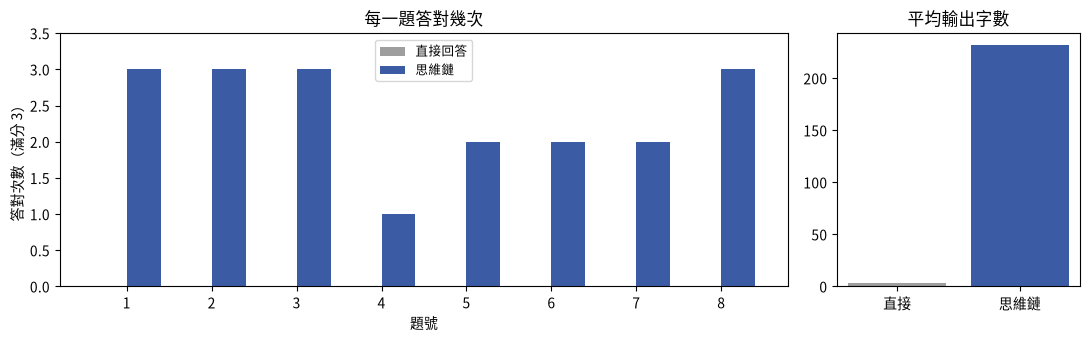

In [5]:
def per_question(rows):
    return [sum(r["對"] for r in rows if r["題號"] == i + 1) for i in range(len(PROBLEMS))]


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [3, 1]})
idx = range(1, len(PROBLEMS) + 1)
ax1.bar([i - 0.2 for i in idx], per_question(direct_rows), width=0.4, color="#9e9e9e", label="直接回答")
ax1.bar([i + 0.2 for i in idx], per_question(cot_rows), width=0.4, color="#3b5ba5", label="思維鏈")
ax1.set_xticks(list(idx))
ax1.set_xlabel("題號")
ax1.set_ylabel("答對次數（滿分 3）")
ax1.set_ylim(0, 3.5)
ax1.legend(fontsize=9)
ax1.set_title("每一題答對幾次")

lengths = [sum(r["字數"] for r in rows) / len(rows) for rows in (direct_rows, cot_rows)]
ax2.bar(["直接", "思維鏈"], lengths, color=["#9e9e9e", "#3b5ba5"])
ax2.set_title("平均輸出字數")
plt.tight_layout()
plt.show()

準確率提高的代價是輸出長了幾十倍：要付更多 token、使用者要等更久。
所以 CoT 不是每題都加，而是留給**需要多步推理**的任務。

## Step 5：看一個 CoT 也算錯的例子

CoT 不保證對。把思維鏈答錯的那幾次印出來，看錯在哪一步。

In [6]:
wrong = [r for r in cot_rows if not r["對"]]
print(f"思維鏈答錯 {len(wrong)} 次")
for r in wrong[:2]:
    print(f"\n=== 第 {r['題號']} 題，標準答案 {PROBLEMS[r['題號'] - 1][1]}")
    print(r["輸出"][-400:])

思維鏈答錯 5 次

=== 第 4 題，標準答案 1205
1. 工單建立時間：09:40
2. 第一次回覆時間：09:40 + 03:50 = 13:30
3. 結案時間：13:30 + 01:50 = 15:20

答案：1520

=== 第 4 題，標準答案 1205
建立時間為 09:40。

第一次回覆用了 35 分鐘，所以第一次回覆後的時間是：
09:40 + 00:35 = 10:15

之後又過了 1 小時 50 分鐘才結案，所以結案時間為：
10:15 + 1:50 = 11:45

答案：1145


常見情況：讀錯題目條件（例如把「其餘 20 分鐘」當成整整 60 分鐘），或時間換算（分鐘進位到小時）出錯。
這也是 CoT 的另一個好處：**錯在哪一步看得到**，可以針對那一步加約束，或把那一步交給程式算。

關於推理模型（例如 DeepSeek-R1、Qwen3 thinking 模式）：「先想再答」已經訓練進模型裡，
提示詞的重點改成寫清楚**怎樣算對**（像本例的「最後一行寫答案：」與評分程式），不必再教它怎麼想。

## Step 6：提示詞串接——一步只做一件事

情境：一場事故後，值班頻道留下一堆雜亂的訊息。要產出兩份東西：給主管的三句摘要、給客戶的公告。

一個 prompt 全包也行，但中間出錯你看不到。串接的做法是拆成三步，前一步的輸出是後一步的輸入：

![提示詞串接流程：抽時間軸、程式檢查、兩份文件](images/prompt_chaining.jpg)

*圖：圓是一次模型呼叫，菱形是程式檢查。時間軸通過檢查後才分給兩個下游步驟；客戶公告後面再接一道「內部用語？」檢查，不合格就回頭重寫（朱紅）。*

In [7]:
chat_log = """[14:02] 阿哲：付款服務 5xx 開始飆，誰在看？
[14:05] 小葵：我在看，資料庫連線池滿了，80 條全佔住
[14:09] 小葵：找到了，報表排程 14:00 跑了一條沒加索引的大查詢，把連線都卡住
[14:11] 阿哲：先把報表排程停掉
[14:13] 小葵：排程停了，連線在釋放
[14:18] Ken：客服這邊收到 12 張客訴，都是付款失敗
[14:21] 小葵：5xx 回到正常水位
[14:30] 阿哲：確認恢復，報表那條查詢明天補索引再開排程"""

STEP1 = """從 <log> 的值班訊息中抽出事故時間軸。
規則：
- 每行格式：HH:MM 事件（10 字到 25 字）
- 只列跟事故發生、診斷、處置、恢復有關的事件
- 依時間排序，只輸出時間軸，不要其他文字
- 使用繁體中文
<log>
{log}
</log>"""

t0 = time.time()
timeline = ask(STEP1.format(log=chat_log))
t_step1 = time.time() - t0
print(timeline)

14:02 付款服務 5xx 開始飆
14:05 資料庫連線池滿了
14:09 报表排程 14:00 跑了一條沒加索引的大查詢
14:11 排程停掉
14:13 连線釋放
14:21 5xx 回到正常水位
14:30 確認恢復


## Step 7：步驟之間插一道程式檢查

這是串接最大的好處：中間結果是看得到、檢查得到的東西。
這裡檢查兩件事：每行都是 `HH:MM` 開頭、時間有排序。不合格就不要往下送。

In [8]:
def check_timeline(text: str) -> list[str]:
    problems = []
    lines = [l.strip() for l in text.splitlines() if l.strip()]
    times = []
    for l in lines:
        m = re.match(r"^(\d{1,2}):(\d{2})\s+\S", l)
        if not m:
            problems.append(f"格式不對：{l!r}")
        else:
            times.append(int(m.group(1)) * 60 + int(m.group(2)))
    if times != sorted(times):
        problems.append("時間沒有排序")
    if len(lines) < 3:
        problems.append("事件太少")
    return problems


issues = check_timeline(timeline)
print("檢查結果：", issues or "通過")

檢查結果： 通過


## Step 8：用時間軸寫兩份文件

第 2、3 步只看時間軸，不看原始訊息。這樣兩份文件說的事實一定一致，而且不會把同事的名字、內部抱怨帶到客戶公告裡。

In [9]:
STEP2 = """你是 SRE 主管的助理。根據 <timeline> 寫三句話的事故摘要給主管：
第一句：發生什麼、影響多久；第二句：根因；第三句：後續行動。只輸出這三句，使用繁體中文。
<timeline>
{timeline}
</timeline>"""

STEP3 = """你是星帆雲端的客服公告撰寫員。根據 <timeline> 寫一則給客戶的公告，80 字以內。
約束：不提任何員工名字、不提內部系統名稱（例如連線池、排程、索引），語氣誠懇，說明影響時段與目前狀態，使用繁體中文。
<timeline>
{timeline}
</timeline>"""

t0 = time.time()
manager_note = ask(STEP2.format(timeline=timeline))
t_step2 = time.time() - t0

t0 = time.time()
customer_note = ask(STEP3.format(timeline=timeline))
t_step3 = time.time() - t0

print("【主管摘要】\n" + manager_note)
print("\n【客戶公告】\n" + customer_note)

【主管摘要】
第一句：付款服務從14:02開始出現大量5xx錯誤，影響時間約為35分鐘。
第二句：事故的根因是報表排程在14:00時執行了一個未加索引的大查詢，導致資料庫連線池滿，無法處理新的請求。
第三句：後續行動包括優化報表查詢以減少資料庫負載，並定期監控資料庫連線池，確保其容量充足。

【客戶公告】
尊敬的客戶，您好。我們的付款服務於今日14:02開始出現暫時性問題，因資料庫連線池滿，導致14:09報表排程執行了一個未加索引的大查詢，從而影響了服務。我們已於14:11停止排程並釋放連線，問題於14:21解決，現已確認恢復正常。感謝您的耐心等待，如有不便，我們深感抱歉。如有其他問題，請洽顧問。祝您使用愉快。


對照組：一個 prompt 全包。

In [10]:
ALL_IN_ONE = """根據 <log> 的值班訊息，輸出兩段：
1. 給主管的三句摘要（發生什麼、根因、後續行動）
2. 給客戶的公告，80 字以內，不提員工名字和內部系統名稱
<log>
{log}
</log>"""

t0 = time.time()
one_shot = ask(ALL_IN_ONE.format(log=chat_log))
t_one = time.time() - t0
print(one_shot)

### 給主管的摘要
1. **發生什麼**：付款服務出現 5xx 故障，導致連線池滿，報表排程的查詢阻塞了連線。
2. **根因**：報表排程在 14:00 進行了一次未加索引的大查詢，阻塞了連線池。
3. **後續行動**：立即停止報表排程，並確認故障已恢復，明天補加索引後再重新啟動排程。

### 給客戶的公告
客服收到 12 起付款失敗客訴，付款服務已恢復正常。


客戶公告最怕漏出內部用語（「連線池」「小葵」）。不要用眼睛看，用程式檢查兩個版本：

In [11]:
INTERNAL = ["阿哲", "小葵", "Ken", "連線池", "排程", "索引", "5xx"]


def leaks(text: str) -> list[str]:
    return [w for w in INTERNAL if w in text]


print("串接版客戶公告洩漏：", leaks(customer_note) or "無")
# 全包版只檢查「客戶公告」那一段：取最後一次出現「公告」之後的文字
one_shot_customer = one_shot[one_shot.rfind("公告"):]
print("全包版客戶公告洩漏：", leaks(one_shot_customer) or "無")

串接版客戶公告洩漏： ['連線池', '排程', '索引']
全包版客戶公告洩漏： 無


兩個版本都可能漏，每次跑結果也不同。串接版常見的漏法是：第 1 步的時間軸本身就寫著「連線池」「排程」，第 3 步照抄。
只靠 prompt 裡的一句「不提內部系統名稱」擋不住；全包版則是整件事都在一次呼叫裡，漏了也沒有地方插手。

串接真正的好處在這裡：第 3 步是獨立的一次呼叫，可以在它後面接一道程式檢查，不合格就把問題回饋給模型重寫。

In [12]:
def write_customer_note(timeline: str, max_tries: int = 3) -> tuple[str, int]:
    messages = [{"role": "user", "content": STEP3.format(timeline=timeline)}]
    for attempt in range(1, max_tries + 1):
        note = chat(messages, temperature=0.3).strip()
        found = leaks(note)
        print(f"第 {attempt} 次：洩漏 {found or '無'}")
        if not found:
            return note, attempt
        messages = messages + [
            {"role": "assistant", "content": note},
            {"role": "user", "content": f"公告裡出現了內部用語：{'、'.join(found)}。"
                                        "請改用客戶聽得懂的說法（例如「系統異常」「後台作業」）重寫，只輸出公告。"},
        ]
    return note, max_tries


t0 = time.time()
customer_note, tries = write_customer_note(timeline)
t_step3 = time.time() - t0
print("\n【客戶公告（檢查後）】\n" + customer_note)

第 1 次：洩漏 ['連線池', '排程', '5xx']
第 2 次：洩漏 無

【客戶公告（檢查後）】
尊敬的客戶，您好。我們在14:02發現付款服務出現問題，14:09因資料庫後台作業滿載導致報表計算暫停。我們已於14:11停止相關計算並於14:13釋放後台作業。目前問題已於14:21解決，付款服務回復正常。我們已於14:30確認系統恢復正常。感謝您的耐心等待，如有其他問題請洽詢。


## Step 9：把串接畫成時間軸

串接的代價是呼叫次數變多。把每一步花的時間畫出來（第 3 步包含重寫的次數；第 2、3 步互不相依，正式系統可以平行跑）。

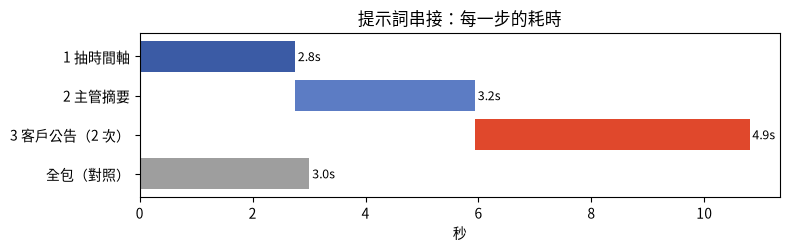

In [13]:
fig, ax = plt.subplots(figsize=(8, 2.6))
steps = [("1 抽時間軸", 0, t_step1, "#3b5ba5"),
         ("2 主管摘要", t_step1, t_step2, "#5c7cc4"),
         (f"3 客戶公告（{tries} 次）", t_step1 + t_step2, t_step3, "#e0482c"),
         ("全包（對照）", 0, t_one, "#9e9e9e")]
for row, (label, start, dur, color) in enumerate(steps):
    ax.barh(row, dur, left=start, color=color)
    ax.text(start + dur + 0.05, row, f"{dur:.1f}s", va="center", fontsize=9)
ax.set_yticks(range(len(steps)), [s[0] for s in steps])
ax.invert_yaxis()
ax.set_xlabel("秒")
ax.set_title("提示詞串接：每一步的耗時")
plt.tight_layout()
plt.show()

## 試試看

1. 在 Step 4 加第三種問法：few-shot CoT（先給一題有完整步驟的範例）。準確率比 zero-shot CoT 高嗎？
2. 第 4 題（時間換算）常算錯。改成「讓模型只寫算式，由 Python 算結果」，把模型不擅長的那一步交給程式。
3. 換個做法擋洩漏：在第 1 步就規定時間軸用客戶看得懂的詞。比較「源頭改 prompt」和「出口加檢查」哪個穩。

## 小結

- 思維鏈讓模型先寫中間步驟，後面的 token 就能看著前面的結果算；準確率上升，代價是字數與時間。
- 串接把大任務拆成小步，步驟之間可以插程式檢查、不合格就回饋重寫，也能控制每一步看得到哪些資料。
- 這兩招都還是「用文字要求」格式；下一本 Lab 2-03 讓程式真正拿到保證合格的 JSON。